<a href="https://colab.research.google.com/github/AkanoFah/dl-image-classification/blob/main/cifar10_cnn.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Capstone — Build, Train & Report a Deep Learning Model

This is **your** project. Across the course you built — by hand, on toy numbers in
the sandbox — tensors, the training loop, CNNs, RNNs/LSTMs, regularization, and the
habit of reading loss curves. Now you put it all together on a **real dataset you
choose**, and you are judged on a **held-out test set** you only touch once.

Unlike the weekly labs, this notebook is **mostly scaffold**. It gives you the
boring-but-essential spine — `device`/seed setup, `train()` / `evaluate()` /
`plot_curves()`, and a one-shot test-evaluation cell — so you can spend your effort
on the part that matters: the **model** and the **experiments**. Everything marked
**🔧 TODO** is yours to fill in. The notebook will not learn anything until you do.

> **Runtime → Change runtime type → T4 GPU** before you start. Then run the setup
> cell and confirm it prints `cuda`.

---

## Choose your track

Pick **one** track below and uncomment its data-loading stub in Beat 3. All three
use a *real* public dataset and target a model family you already met in the course.
You are free to invent your own task instead (any real dataset + a model you train)
— these three are just well-scoped starting points.

| Track | Dataset (real, auto-downloaded) | Model you build | Beat this baseline |
|---|---|---|---|
| **A · Vision** | **CIFAR-10** — 60k 32×32 colour photos, 10 classes | a **CNN** (Conv → ReLU → Pool …) | majority class = **10%**; aim **> 65%** test accuracy |
| **B · Text** | **Names-by-language** — ~20k surnames, 18 languages (PyTorch's char-RNN dataset) | a char-level **LSTM** classifier | majority class (English) ≈ **27%**; aim **> 70%** |
| **C · Tabular** | **Penguins** — 344 rows, 7 features, 3 species (seaborn) | an **MLP** | majority class ≈ **44%**; aim **> 95%** |

Each track is sized to train in **under ~5 minutes on a T4**. The spine below is
**track-agnostic**: write your dataset loader and model so that `train_loader`,
`val_loader`, `test_loader`, and `model` exist, and the generic `train()` /
`evaluate()` helpers just work.

> **The one rule that defines this capstone:** *tune on validation, report on test.*
> Choose your model, learning rate, epochs, and regularization using the **validation**
> set. Touch the **test** set exactly **once**, at the very end, for the number you
> report. Peeking at test while tuning turns it into a second validation set and
> quietly inflates your result — the rubric checks for this.

## 1 · Setup, GPU check & the spine

Run this once. It imports everything, fixes the seed so your runs are reproducible
(the rubric expects a fixed seed), picks the GPU, and defines the **spine** you'll
reuse no matter which track you chose:

- `accuracy(logits, y)` — exact-match accuracy for a batch of logits.
- `train(...)` — the generic five-step training loop with a validation pass each
  epoch; returns the per-epoch `history`.
- `evaluate(...)` — a no-grad forward pass returning `(loss, accuracy)`.
- `plot_curves(history)` — train-vs-val loss and accuracy, the diagnostic you learned
  to read in the labs.

These are deliberately model-agnostic: they assume a classifier whose `model(x)`
returns class **logits** and whose loader yields `(x, y)` batches. That covers all
three tracks. (Doing a regression or a language model instead? Swap
`CrossEntropyLoss`/accuracy for MSE/perplexity — the loop shape is identical.)

In [7]:
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

# --- reproducibility: fix the seed so your reported numbers reproduce -------
SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# --- device: train on the GPU if Colab gave you one -------------------------
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)
if device == "cpu":
    print("WARNING: no GPU. Runtime -> Change runtime type -> T4 GPU, then re-run.")


@torch.no_grad()
def accuracy(logits, y):
    """Fraction correct for a batch of class logits vs integer labels."""
    return (logits.argmax(dim=-1) == y).float().mean().item()


@torch.no_grad()
def evaluate(model, loader, loss_fn):
    """One no-grad pass over `loader`; returns (mean loss, accuracy)."""
    model.eval()                                  # dropout off, BN uses running stats
    total_loss, correct, n = 0.0, 0, 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)         # same device as the model
        logits = model(x)
        total_loss += loss_fn(logits, y).item() * len(y)
        correct += (logits.argmax(dim=-1) == y).sum().item()
        n += len(y)
    return total_loss / n, correct / n


def train(model, train_loader, val_loader, *, epochs=10, lr=1e-3,
          weight_decay=0.0, loss_fn=None, max_grad_norm=None):
    """The five-step loop (forward, loss, zero_grad, backward, step) with a
    validation pass each epoch. Returns a per-epoch history dict."""
    model = model.to(device)                      # move the model once, before the loop
    loss_fn = loss_fn or nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:                 # the five steps, per batch
            x, y = x.to(device), y.to(device)     # data on the SAME device as the model
            logits = model(x)                     # 1. forward
            loss = loss_fn(logits, y)             # 2. loss
            optimizer.zero_grad()                 # 3. clear last batch's grads
            loss.backward()                       # 4. backprop
            if max_grad_norm is not None:         # clip for RNNs/LSTMs (Track B)
                nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()                      # 5. update the weights

        tr_loss, tr_acc = evaluate(model, train_loader, loss_fn)
        va_loss, va_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        print(f"epoch {epoch + 1:2d}/{epochs}  "
              f"train_loss={tr_loss:.3f} acc={tr_acc:.2%}  |  "
              f"val_loss={va_loss:.3f} acc={va_acc:.2%}")
    return history


def plot_curves(history):
    """Train vs. validation loss and accuracy — read the gap (labs L5/L11)."""
    epochs = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
    ax1.plot(epochs, history["train_loss"], "-o", label="train")
    ax1.plot(epochs, history["val_loss"], "-o", label="val")
    ax1.set(xlabel="epoch", ylabel="loss", title="Loss")
    ax1.legend(); ax1.grid(alpha=0.3)
    ax2.plot(epochs, history["train_acc"], "-o", label="train")
    ax2.plot(epochs, history["val_acc"], "-o", label="val")
    ax2.set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
    ax2.legend(); ax2.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()


print("spine ready: accuracy(), evaluate(), train(), plot_curves()")

device: cuda
spine ready: accuracy(), evaluate(), train(), plot_curves()


## 2 · 🔧 Load your real dataset (with a train / val / **test** split)

**Uncomment exactly one block below** (your chosen track). Each one downloads a real
dataset over the internet (Colab has it), builds a model-agnostic train/val/test
split, and exposes the **same four names** the spine expects:

```
train_loader   val_loader   test_loader   classes
```

plus whatever your model needs (`in_features`, `vocab_size`, `n_classes`, …). Keeping
the interface identical across tracks is what lets the generic `train()` / `evaluate()`
helpers work unchanged.

> **🔧 Your turn — the split is the load-bearing part.** Carve out a **test** set and
> *do not look at it* until the final cell. Tune everything on **val**. Each stub
> below does a clean 3-way split with the fixed `SEED`; read it, and if you bring your
> own dataset, replicate that discipline (no overlap, no peeking).

In [8]:
# ============================================================================
# TRACK A · VISION — CIFAR-10 (real 32x32 colour photos, 10 classes)
# Build a CNN. This block is ACTIVE so the notebook runs end-to-end out of the
# box; comment it out if you pick Track B or C.
# ============================================================================
from torch.utils.data import DataLoader, random_split, Subset
from torchvision import datasets, transforms

# What's real/messy: natural photos with backgrounds, lighting, and pose
# variation. Some classes look alike (cat vs dog, automobile vs truck) -- your
# confusion matrix later will show exactly which.
norm = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616))
train_tf = transforms.Compose([                 # augment ONLY the training set
    transforms.RandomHorizontalFlip(),
    transforms.RandomCrop(32, padding=4),
    transforms.ToTensor(), norm,
])
eval_tf = transforms.Compose([transforms.ToTensor(), norm])   # never augment val/test

# CIFAR's official split is 50k train + 10k test. We hold the 10k test out
# untouched, and carve a validation set off the training data.
full_train = datasets.CIFAR10("./data", train=True, download=True, transform=train_tf)
test_set = datasets.CIFAR10("./data", train=False, download=True, transform=eval_tf)

# Subset to train fast on a T4 (~3-4 min). Use all 50k for a stronger result.
SUBSET = 50000
g = torch.Generator().manual_seed(SEED)
idx = torch.randperm(len(full_train), generator=g)[:SUBSET].tolist()
n_val = SUBSET // 5
train_idx, val_idx = idx[n_val:], idx[:n_val]
train_set = Subset(full_train, train_idx)
# val must NOT be augmented -> point it at a non-augmented copy of the data
val_base = datasets.CIFAR10("./data", train=True, download=True, transform=eval_tf)
val_set = Subset(val_base, val_idx)

batch_size = 128
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_set, batch_size=batch_size)
test_loader = DataLoader(test_set, batch_size=batch_size)
classes = full_train.classes                    # ['airplane', 'automobile', ...]
print(f"train={len(train_set)} val={len(val_set)} test={len(test_set)} "
      f"classes={len(classes)}")

100%|██████████| 170M/170M [58:09<00:00, 48.9kB/s]


train=40000 val=10000 test=10000 classes=10


## 3 · Look at the data

Seeing the data *is* the real-dataset experience — it's where you notice the class
imbalance, the messy rows, the look-alike classes. The cell below shows a class
histogram + a sample for **Track A**. If you switched tracks, adapt it: show a few
raw surnames per language (B) or `df.head()` and `df.describe()` (C).

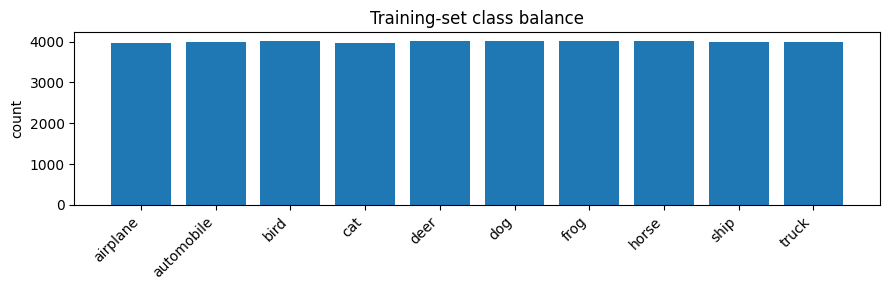

majority-class baseline (train): 10.1%


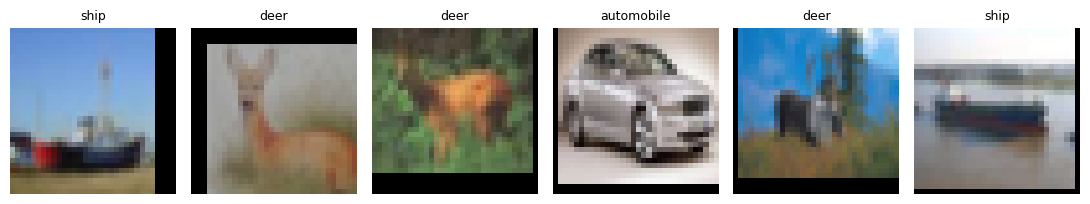

In [9]:
# EDA for the ACTIVE track (A · CIFAR-10). Adapt for B (print sample names per
# class) or C (df.head(), df["species"].value_counts(), a pairplot).
import collections

# 1. Class histogram of the training split -- is it balanced?
counts = collections.Counter(int(train_set[i][1]) for i in range(len(train_set)))
plt.figure(figsize=(9, 3))
plt.bar([classes[k] for k in sorted(counts)], [counts[k] for k in sorted(counts)])
plt.xticks(rotation=45, ha="right"); plt.ylabel("count")
plt.title("Training-set class balance"); plt.tight_layout(); plt.show()
print("majority-class baseline (train):",
      f"{max(counts.values()) / sum(counts.values()):.1%}")

# 2. A few sample images with their labels.
inv = transforms.Normalize((-0.4914 / 0.2470, -0.4822 / 0.2435, -0.4465 / 0.2616),
                            (1 / 0.2470, 1 / 0.2435, 1 / 0.2616))
fig, axes = plt.subplots(1, 6, figsize=(11, 2.2))
for ax, i in zip(axes, range(6)):
    img, label = train_set[i]
    ax.imshow(inv(img).permute(1, 2, 0).clamp(0, 1).numpy())
    ax.set_title(classes[label], fontsize=9); ax.axis("off")
plt.tight_layout(); plt.show()

## 4 · 🔧 Build your model

This mirrors what you built from scratch in the labs — **read it, and try writing it
yourself before running.** The scaffold gives a working starter for each track so the
notebook trains immediately; the rubric expects *you* to design and justify the
architecture, so treat the starter as a baseline to **improve on**, not a final answer.

> **🔧 Your turn — define `model`.** Uncomment the starter for your track (the **CNN**
> for A is active by default). Then make it yours: depth, width, dropout, an extra conv
> block, a second LSTM layer — whatever you'll defend in your report. `model(x)` must
> return class **logits**; the spine does the rest.

In [10]:
# ---- TRACK A · CNN (active) -- Conv -> ReLU -> Pool, twice, then a linear head.
# Mirrors the L6 recipe; CIFAR is 3-channel 32x32 (-> 16x16 -> 8x8).
class CNN(nn.Module):
    def __init__(self, n_classes=10, p_drop=0.25):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 32x32 -> 16x16
            nn.Conv2d(32, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2),                                  # 16x16 -> 8x8
        )
        self.head = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 8 * 8, 128), nn.ReLU(),
            nn.Dropout(p_drop),                               # regularization (L5)
            nn.Linear(128, n_classes),
        )

    def forward(self, x):                  # x: (batch, 3, 32, 32)
        return self.head(self.features(x))

model = CNN(n_classes=len(classes))


n_params = sum(p.numel() for p in model.parameters())
print(model)
print(f"trainable parameters: {n_params:,}")

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
trainable parameters: 545,098


## 5 · 🔧 Train

The five-step loop lives in `train()` (Beat 1) — you just call it. Keep the first run
**fast** (few epochs / the subset) so you get a signal in minutes, then scale up once
the wiring works.

> **🔧 Your turn — run it, then tune to beat the baseline.** Call `train(...)`, read
> the printed `val_acc`, and iterate: learning rate, epochs, `weight_decay`, dropout,
> model size, augmentation. **For Track B (LSTM)** pass `max_grad_norm=1.0` to clip
> exploding gradients. Tune on **val** only — the test set stays sealed until Beat 7.

> **Cheapest sanity check first:** if a fresh model won't drive the loss down at all,
> *overfit one tiny batch* (high lr, many steps, no dropout). If it can't memorise a
> handful of examples, the bug is in the wiring (a wrong shape, a frozen layer), not
> the hyperparameters — fix that before a long run.

In [11]:
# 🔧 Your main run. Tune these on VALIDATION; do not touch test yet.
history = train(
    model,
    train_loader,
    val_loader,
    epochs=15,            # 🔧 enough to see val accuracy plateau
    lr=1e-3,             # 🔧 if loss diverges/NaN, drop 10x; if it crawls, raise it
    weight_decay=1e-4,   # 🔧 L2 regularization (Track B: also max_grad_norm=1.0)
)

epoch  1/15  train_loss=1.424 acc=49.15%  |  val_loss=1.346 acc=51.91%
epoch  2/15  train_loss=1.246 acc=55.50%  |  val_loss=1.180 acc=58.00%
epoch  3/15  train_loss=1.154 acc=58.81%  |  val_loss=1.070 acc=61.57%
epoch  4/15  train_loss=1.064 acc=62.08%  |  val_loss=0.998 acc=64.05%
epoch  5/15  train_loss=1.048 acc=62.44%  |  val_loss=0.986 acc=64.98%
epoch  6/15  train_loss=0.970 acc=65.71%  |  val_loss=0.891 acc=68.30%
epoch  7/15  train_loss=0.943 acc=66.81%  |  val_loss=0.881 acc=68.52%
epoch  8/15  train_loss=0.913 acc=68.09%  |  val_loss=0.848 acc=70.18%
epoch  9/15  train_loss=0.900 acc=68.28%  |  val_loss=0.835 acc=70.06%
epoch 10/15  train_loss=0.858 acc=69.92%  |  val_loss=0.798 acc=71.81%
epoch 11/15  train_loss=0.851 acc=70.16%  |  val_loss=0.810 acc=71.48%
epoch 12/15  train_loss=0.826 acc=71.35%  |  val_loss=0.786 acc=72.63%
epoch 13/15  train_loss=0.810 acc=71.84%  |  val_loss=0.771 acc=72.85%
epoch 14/15  train_loss=0.826 acc=71.08%  |  val_loss=0.774 acc=72.89%
epoch 

### 🔧 (Optional) Diagnose & fix a broken run

This cell is **isolated** — it trains its own throwaway model, so it never touches your
real `model` or `history` above. It has a **planted bug**: the classic training-loop
mistake from the labs. Run it, watch the loss *refuse to fall*, then **find and fix the
one missing line** and watch it learn.

> **🔧 Your turn:** what one step of the five-step heartbeat is missing? Why does
> leaving it out make the gradient grow batch-over-batch and the loss lurch? Fix it,
> re-run, and confirm the loss now drops.

In [ ]:
# 🔧 BROKEN ON PURPOSE -- find the missing line. (Isolated: uses its own model.)
import copy


def overfit_one_batch_demo():
    torch.manual_seed(SEED)
    x, y = next(iter(train_loader))
    x, y = x.to(device), y.to(device)
    probe = copy.deepcopy(model)                    # a fresh, independent copy
    for m in probe.modules():                       # re-init so it starts untrained
        if hasattr(m, "reset_parameters"):
            m.reset_parameters()
    probe = probe.to(device)
    opt = torch.optim.SGD(probe.parameters(), lr=0.1)   # plain SGD, high lr (overfit 1 batch)
    loss_fn = nn.CrossEntropyLoss()
    probe.train()
    for step in range(60):
        logits = probe(x)
        loss = loss_fn(logits, y)
        # opt.zero_grad()        # <-- 🔧 BUG: this line is commented out. Restore it!
        loss.backward()
        opt.step()
        if step % 15 == 0:
            print(f"step {step:2d}: loss={loss.item():.4f}")  # should march toward 0
    print("If the loss did NOT fall, you found why: gradients accumulate without "
          "zero_grad().")

overfit_one_batch_demo()

## 6 · Evaluate, experiment & reflect

### Loss curves
Read the gap (L5): close + low = good; train falling while val rises = overfitting;
both high = underfitting. Use this to decide your *next* experiment.

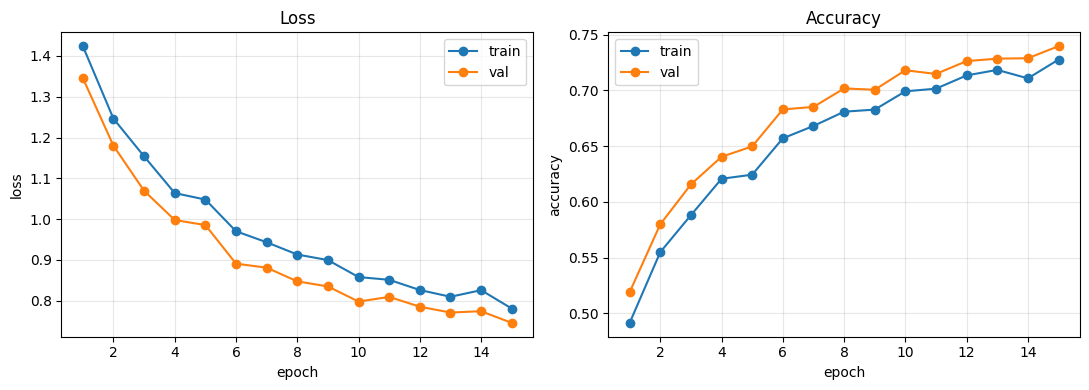

In [12]:
plot_curves(history)

### Confusion matrix on validation
A single accuracy number hides *which* classes get confused. Build the matrix on
**val** (not test) and read off the look-alikes — for CIFAR, expect cat↔dog and
automobile↔truck. (Text/tabular: same matrix; a language-model track would show
generated samples + perplexity instead.)

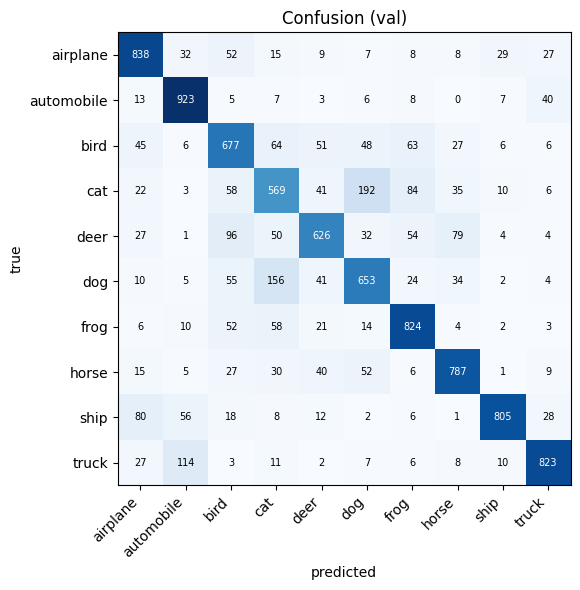

  recall  cat          55.78%
  recall  deer         64.34%
  recall  dog          66.36%
  recall  bird         68.18%
  recall  ship         79.23%
  recall  horse        80.97%
  recall  truck        81.40%
  recall  airplane     81.76%
  recall  frog         82.90%
  recall  automobile   91.21%


In [24]:
@torch.no_grad()
def confusion_matrix(model, loader, n_classes):
    model.eval()
    cm = torch.zeros(n_classes, n_classes, dtype=torch.long)
    for x, y in loader:
        preds = model(x.to(device)).argmax(dim=-1).cpu()
        for t, p in zip(y, preds):
            cm[t, p] += 1
    return cm

cm = confusion_matrix(model_exp2, val_loader, len(classes))
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(classes))); ax.set_xticklabels(classes, rotation=45, ha="right")
ax.set_yticks(range(len(classes))); ax.set_yticklabels(classes)
ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title("Confusion (val)")
for i in range(len(classes)):                    # annotate counts
    for j in range(len(classes)):
        ax.text(j, i, int(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=7)
plt.tight_layout(); plt.show()

# Per-class recall (of the true class c, what fraction did we catch?)
recall = cm.diag() / cm.sum(dim=1).clamp(min=1)
for c, r in sorted(zip(classes, recall.tolist()), key=lambda t: t[1]):
    print(f"  recall  {c:<12} {r:.2%}")

### 🔧 Experiment — beat the baseline, then ablate

Run **at least two** modify-and-observe experiments, changing **one thing at a time**
and re-reading the curves. Fill in the table with **validation** numbers (test stays
sealed). Suggestions: toggle augmentation/dropout, change `lr` or `weight_decay`, add
a layer, widen the model.

| # | Change (vs. baseline) | Val accuracy | Train–val gap | Notes |
|---|---|---|---|---|
| 0 | Baseline: Dropout=0.25, LR=1e-3, WD=1e-4 | 73.97% | -1.20 pp | Best validation accuracy at epoch 15 |
| 1 | Weight decay=0.0 | 73.81% | -1.15 pp | Slightly lower validation accuracy than baseline |
| 2 | Dropout=0.0 | 75.25% | -0.70 pp | Improved validation accuracy; best at epoch 15 |


**Target:** beat your track's stated baseline (A > 65%, B > 70%, C > 95%). State the
trivial baseline you compare against (majority-class accuracy) and your best **val**
number before you open the test set.

Model 1 experiment

In [14]:
model_exp1 = CNN(
    n_classes=len(classes),
    p_drop=0.25
).to(device)

print(model_exp1)

CNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (head): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=4096, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.25, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [15]:
history_exp1 = train(
    model_exp1,
    train_loader,
    val_loader,
    epochs=15,
    lr=1e-3,
    weight_decay=0.0
)

epoch  1/15  train_loss=1.419 acc=48.64%  |  val_loss=1.344 acc=51.16%
epoch  2/15  train_loss=1.272 acc=54.48%  |  val_loss=1.173 acc=57.55%
epoch  3/15  train_loss=1.165 acc=58.63%  |  val_loss=1.079 acc=61.52%
epoch  4/15  train_loss=1.073 acc=61.55%  |  val_loss=0.992 acc=64.67%
epoch  5/15  train_loss=1.031 acc=63.16%  |  val_loss=0.958 acc=65.41%
epoch  6/15  train_loss=0.995 acc=65.16%  |  val_loss=0.925 acc=67.18%
epoch  7/15  train_loss=0.956 acc=66.54%  |  val_loss=0.893 acc=68.28%
epoch  8/15  train_loss=0.920 acc=67.47%  |  val_loss=0.864 acc=69.03%
epoch  9/15  train_loss=0.903 acc=68.37%  |  val_loss=0.842 acc=69.98%
epoch 10/15  train_loss=0.875 acc=69.28%  |  val_loss=0.822 acc=70.67%
epoch 11/15  train_loss=0.855 acc=69.73%  |  val_loss=0.801 acc=71.09%
epoch 12/15  train_loss=0.819 acc=71.41%  |  val_loss=0.782 acc=72.76%
epoch 13/15  train_loss=0.811 acc=71.48%  |  val_loss=0.767 acc=72.76%
epoch 14/15  train_loss=0.825 acc=70.97%  |  val_loss=0.783 acc=72.24%
epoch 

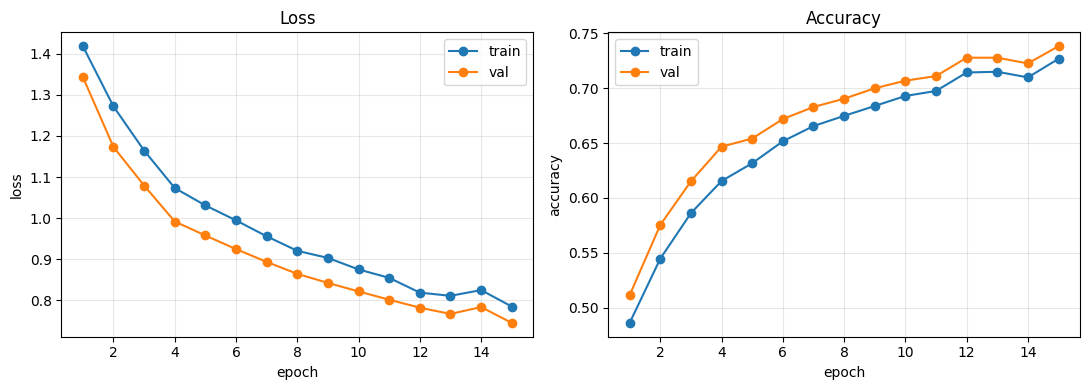

In [16]:
plot_curves(history_exp1)

Model 2 Experiment

In [17]:
model_exp2 = CNN(
    n_classes=len(classes),
    p_drop=0.0
).to(device)

In [18]:
history_exp2 = train(
    model_exp2,
    train_loader,
    val_loader,
    epochs=15,
    lr=1e-3,
    weight_decay=1e-4
)

epoch  1/15  train_loss=1.379 acc=50.63%  |  val_loss=1.283 acc=54.04%
epoch  2/15  train_loss=1.183 acc=57.67%  |  val_loss=1.103 acc=60.32%
epoch  3/15  train_loss=1.118 acc=60.46%  |  val_loss=1.024 acc=63.30%
epoch  4/15  train_loss=1.026 acc=63.51%  |  val_loss=0.952 acc=65.86%
epoch  5/15  train_loss=0.983 acc=65.14%  |  val_loss=0.926 acc=66.64%
epoch  6/15  train_loss=0.917 acc=67.68%  |  val_loss=0.844 acc=70.14%
epoch  7/15  train_loss=0.886 acc=69.06%  |  val_loss=0.836 acc=70.27%
epoch  8/15  train_loss=0.862 acc=69.65%  |  val_loss=0.810 acc=71.60%
epoch  9/15  train_loss=0.826 acc=71.17%  |  val_loss=0.794 acc=72.07%
epoch 10/15  train_loss=0.822 acc=70.93%  |  val_loss=0.789 acc=72.59%
epoch 11/15  train_loss=0.809 acc=71.60%  |  val_loss=0.766 acc=73.34%
epoch 12/15  train_loss=0.780 acc=72.43%  |  val_loss=0.761 acc=72.89%
epoch 13/15  train_loss=0.751 acc=73.38%  |  val_loss=0.730 acc=73.99%
epoch 14/15  train_loss=0.740 acc=74.32%  |  val_loss=0.722 acc=74.61%
epoch 

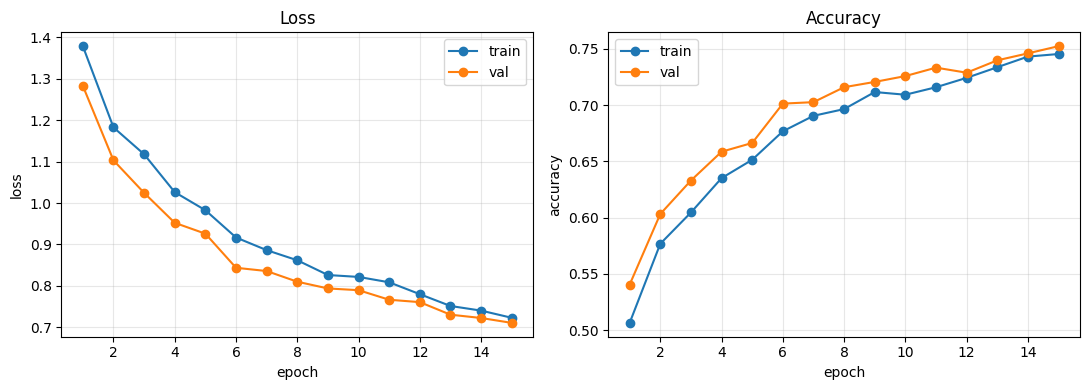

In [19]:
plot_curves(history_exp2)

Best Model

In [20]:
import torch

torch.save(model_exp2.state_dict(), "best_model.pth")
print("Saved model: best_model.pth")

Saved model: best_model.pth


In [21]:
import json

experiment_info = {
    "experiment": "Dropout ablation",
    "dropout": 0.0,
    "learning_rate": 1e-3,
    "weight_decay": 1e-4,
    "epochs": 15,
    "seed": SEED,
    "train_accuracy": 74.55,
    "validation_accuracy": 75.25,
    "best_epoch": 15
}

with open("best_model_config.json", "w") as f:
    json.dump(experiment_info, f, indent=4)

print("Saved config: best_model_config.json")

Saved config: best_model_config.json


In [22]:
from google.colab import files

files.download("best_model.pth")
files.download("best_model_config.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### ✅ Final test evaluation — run this **once**

This is the only time you touch the **test** set. Pick the model + hyperparameters you
settled on using validation, make sure that `model` is trained, and run this cell **a
single time**. The number it prints is the one you report. Re-running it after more
tuning is exactly the test-leakage the rubric penalises — so tune *first*, seal it
*last*.

In [23]:
# ✅ ONE-SHOT held-out test evaluation. Do NOT tune after seeing this number.

import collections
import torch.nn as nn

test_loss, test_acc = evaluate(
    model_exp2,
    test_loader,
    nn.CrossEntropyLoss()
)

majority = max(
    collections.Counter(
        int(test_set[i][1])
        for i in range(len(test_set))
    ).values()
) / len(test_set)

print(f"Majority-class baseline (test): {majority:.2%}")
print(f"FINAL TEST  loss={test_loss:.3f}  accuracy={test_acc:.2%}")
print(
    "Beat baseline:",
    "YES" if test_acc > majority else "NO"
)

Majority-class baseline (test): 10.00%
FINAL TEST  loss=0.736  accuracy=74.73%
Beat baseline: YES


| Metric | Result |
|---|---:|
| Test Loss | 0.736 |
| Test Accuracy | 74.73% |
| Majority-class baseline | 10.00% |
| Target accuracy | >65% |
| Target achieved | Yes |

## 7 · Rubric checklist

Before you submit, tick each box. These mirror the **Capstone rubric** — honest
methodology counts more than a high number.

- [x] **Real dataset, real model.** A public dataset (cited) and a model *you* defined
      and trained — not a pre-trained model called as-is.
- [x] **Honest train / val / test discipline.** A clean 3-way split; the test set was
      touched **exactly once**, at the end. No hyperparameter was chosen by looking at
      test.
- [x] **A baseline, beaten.** You state a trivial baseline (majority-class /
      mean / linear) and your model beats it on the **held-out test** set.
- [x] **At least one form of regularization** (dropout, weight decay, augmentation,
      early stopping) — and you can say *why*.
- [x] **Loss curves + a confusion matrix / metric.** Train-vs-val curves you can read,
      plus a confusion matrix (or per-class metric / generated samples) — not just one
      accuracy number.
- [x] **A fixed seed** so your numbers reproduce.
- [x] **A short written report** (the template below), including one **honest failure
      case**.

## 8 · Report

### Dataset & task

This project uses CIFAR-10, a dataset of 60,000 color images (32 × 32 pixels) across 10 classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, and truck.

I split the data into 40,000 training images, 10,000 validation images, and 10,000 test images. The model predicts one of the 10 classes for each image.

Dataset source: [CIFAR-10](https://www.cs.toronto.edu/~kriz/cifar.html)

### Model & training choices

I built a CNN with two convolutional layers containing 32 and 64 channels. Each layer is followed by ReLU activation and max pooling. A fully connected layer with 128 units then maps the extracted features to 10 class scores.

I trained the model with CrossEntropyLoss and Adam for 15 epochs, using a learning rate of 0.001 and a batch size of 128. I set the random seed to 0. Training images were augmented with random horizontal flips and random crops with padding, then converted to tensors and normalized.

The selected experiment used dropout = 0.0 and weight decay = 0.0001.

### Baseline

The majority-class baseline predicts the most frequent class for every image. Its test accuracy was 10.00%. The CNN performed substantially better, reaching 74.73% test accuracy.

### Final test metric

The selected model achieved a test loss of **0.736** and test accuracy of **74.73%**, exceeding the 65% target. Its accuracy was 64.73 percentage points higher than the 10.00% majority-class baseline.

I selected the model based on validation performance and used the held-out test set for the final evaluation.

### What I tried (ablation)

| Experiment | Dropout | Weight decay | Train accuracy | Validation accuracy | Train − validation gap |
|---|---:|---:|---:|---:|---:|
| Baseline | 0.25 | 0.0001 | 72.77% | 73.97% | −1.20 pp |
| No weight decay | 0.25 | 0.0 | 72.66% | 73.81% | −1.15 pp |
| No dropout | 0.0 | 0.0001 | 74.55% | 75.25% | −0.70 pp |

Removing dropout gave the best validation accuracy, increasing it from 73.97% to 75.25%. Removing weight decay slightly reduced validation accuracy to 73.81%.

Validation accuracy was higher than training accuracy in all three experiments. Random augmentation during training may partly explain this difference. In these runs, dropout did not improve validation performance, while keeping weight decay produced better results than removing it.

### What worked / what failed

The selected CNN achieved 74.73% test accuracy, exceeding the 65% target. On the validation set, automobile had the highest recall at 91.21%, followed by frog at 82.90%. Cat had the lowest recall at 55.78%, while deer, dog, and bird also had lower recall.

The model performed better on some classes than others. To understand which classes it confuses, I would examine the confusion matrix and review misclassified validation images. This could help identify where the model needs improvement.

### With more time

I would generate a confusion matrix and per-class recall for the selected model, then inspect misclassified validation images to find common class confusions. I would use those findings to guide experiments with a deeper CNN or a residual architecture, comparing each change on the same validation split before any final test evaluation.